In [2]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("OpenCV:", cv2.__version__)

from rppg_step1_3 import (inspect_video, load_ground_truth,
                          extract_rgb_signals, VIDEO_PATH, GT_PATH)

print("\n=== STEP 1: video ===")
info = inspect_video(VIDEO_PATH)
for k, v in info.items():
    print(k, ":", v)

print("\n=== STEP 2: ground truth ===")
gt = load_ground_truth(GT_PATH)

OpenCV: 4.14.0

=== STEP 1: video ===
fps : 29.264106
width : 640
height : 480
frame_count_reported : 1547
duration_sec_reported : 52.863395177696525

=== STEP 2: ground truth ===
[GT] raw shape: (3, 1547)
[GT] samples: 1547
[GT] time range: 0.00s -> 52.69s
[GT] average sampling frequency: 29.34 Hz
[GT] HR min/mean/max: 97.0 / 106.7 / 113.0 BPM


[RGB] frames processed: 300
[RGB] frames with no fresh face detection: 0 (last known box was reused for these)
(300, 15)
face detected fraction: 1.0


,frame,time_s,face_detected,forehead_R,forehead_G,forehead_B,left_cheek_R,left_cheek_G,left_cheek_B,right_cheek_R,right_cheek_G,right_cheek_B,combined_R,combined_G,combined_B
0,0,0.000000,1,209.597241,164.882759,162.333793,190.012311,145.682765,144.655303,190.839015,145.621212,144.160038,196.816189,152.062245,150.383045
1,1,0.034172,1,209.576552,164.677241,162.277241,190.061553,145.720644,144.708333,190.671402,145.452652,144.282197,196.769835,151.950179,150.422591
2,2,0.068343,1,209.491724,164.606207,162.152414,190.107955,145.695076,144.793561,190.478220,145.413826,143.981061,196.692633,151.905036,150.309012
3,3,0.102515,1,209.244068,164.232542,161.629831,188.314617,144.388592,143.485740,189.853994,145.108356,143.408632,195.804226,151.243163,149.508067
4,4,0.136686,1,209.126780,164.028475,161.750508,188.826287,144.698529,143.745404,190.427083,145.361742,143.994318,196.126717,151.362915,149.830077


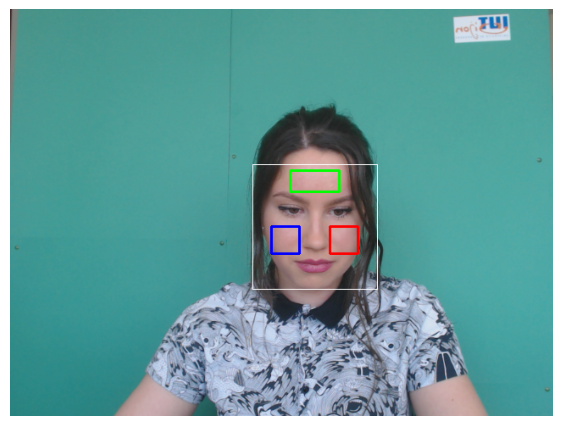

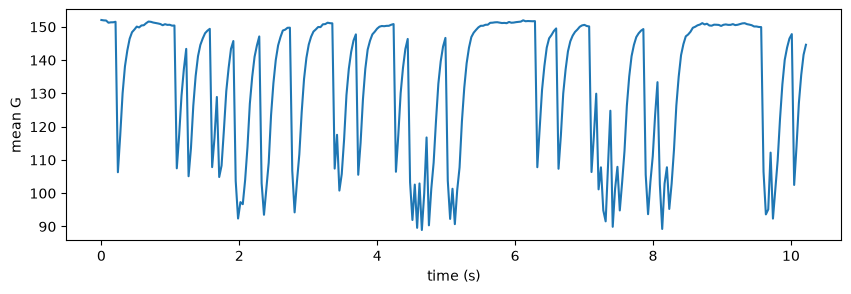

In [3]:
df = extract_rgb_signals(VIDEO_PATH, info["fps"], max_frames=300)
print(df.shape)
print("face detected fraction:", df["face_detected"].mean())
display(df.head())

img = cv2.imread("outputs/subject1/debug_roi_frame0.png")
plt.figure(figsize=(7, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(df["time_s"], df["combined_G"])
plt.xlabel("time (s)")
plt.ylabel("mean G")
plt.show()

[fixed] frames: 300, rejected detections: 0, start box: [286. 184. 147. 147.]


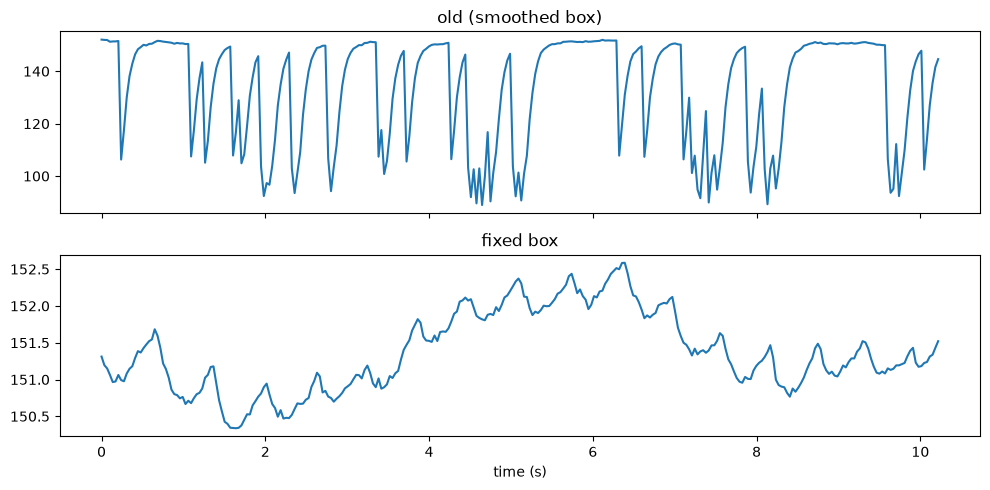

In [4]:
from rppg_step1_3 import detect_face_box, skin_regions_from_box, mean_rgb_rect

def extract_rgb_v2(video_path, max_frames=None, mode="fixed",
                   n_init=30, max_jump=15, alpha=0.1):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)

    # starting box = median of detections in the first n_init frames
    dets = []
    for _ in range(n_init):
        ok, f = cap.read()
        if not ok:
            break
        b = detect_face_box(f)
        if b is not None:
            dets.append(b)
    if not dets:
        raise RuntimeError("No face found in the first frames")
    box = np.median(np.array(dets, dtype=float), axis=0)
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    rows, idx, rejected = [], 0, 0
    while True:
        ok, frame_bgr = cap.read()
        if not ok or (max_frames is not None and idx >= max_frames):
            break
        h_img, w_img = frame_bgr.shape[:2]
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

        if mode == "gated":      # slowly follow the face, ignore sudden jumps
            nb = detect_face_box(frame_bgr)
            if nb is not None:
                shift = np.hypot((nb[0] + nb[2] / 2) - (box[0] + box[2] / 2),
                                 (nb[1] + nb[3] / 2) - (box[1] + box[3] / 2))
                ratio = nb[2] / box[2]
                if shift <= max_jump and 0.85 <= ratio <= 1.15:
                    box = (1 - alpha) * box + alpha * np.array(nb, dtype=float)
                else:
                    rejected += 1

        regions = skin_regions_from_box(box, w_img, h_img)
        row = {"frame": idx, "time_s": idx / fps}
        for name, rect in regions.items():
            row[f"{name}_R"], row[f"{name}_G"], row[f"{name}_B"] = mean_rgb_rect(frame_rgb, rect)
        for c in "RGB":
            row[f"combined_{c}"] = float(np.nanmean([row[f"{n}_{c}"] for n in regions]))
        rows.append(row)
        idx += 1

    cap.release()
    print(f"[{mode}] frames: {idx}, rejected detections: {rejected}, start box: {np.round(box, 1)}")
    return pd.DataFrame(rows)

df_fixed = extract_rgb_v2(VIDEO_PATH, max_frames=300, mode="fixed")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(df["time_s"], df["combined_G"]);       ax[0].set_title("old (smoothed box)")
ax[1].plot(df_fixed["time_s"], df_fixed["combined_G"]); ax[1].set_title("fixed box")
ax[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

[fixed] frames: 1547, rejected detections: 0, start box: [286. 184. 147. 147.]
Estimated heart rate: 107.4 BPM
Ground truth average: 106.7 BPM
Difference: 0.7 BPM


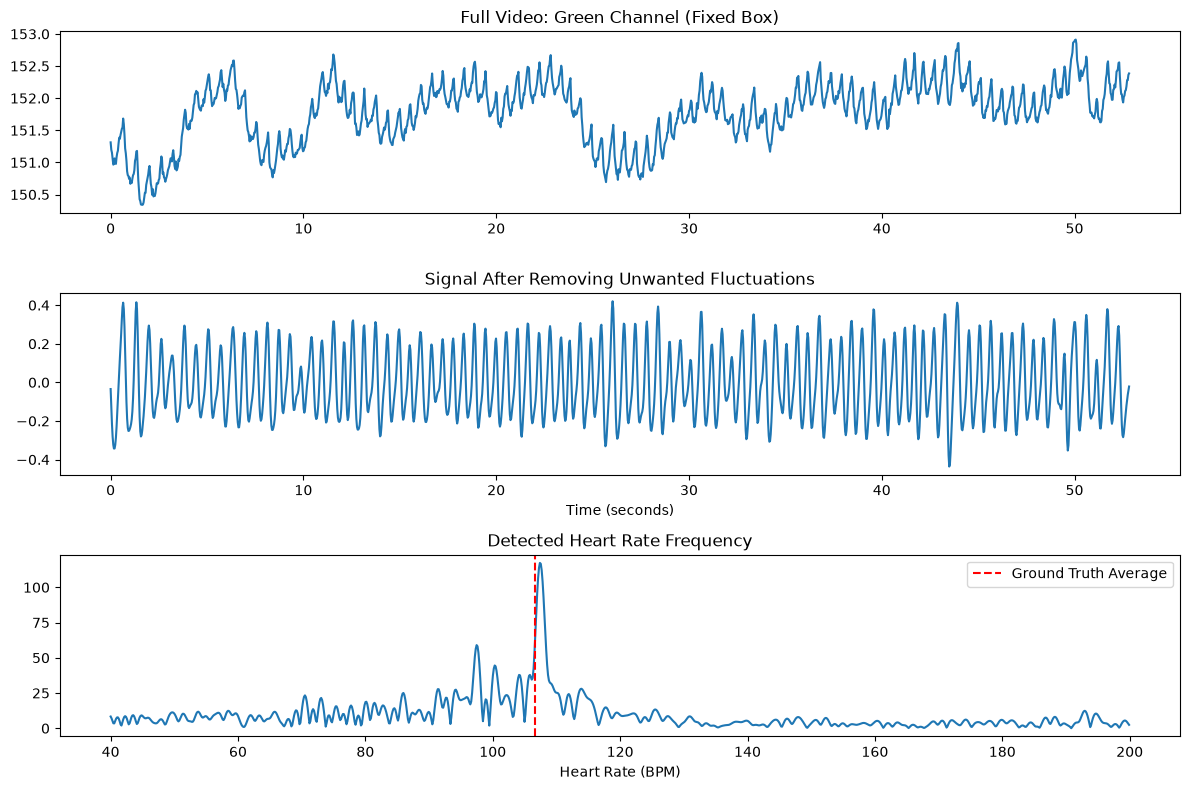

In [6]:
from scipy.signal import butter, filtfilt

def keep_heart_waves(x, fs, low=0.7, high=4.0):
    b, a = butter(3, [low / (fs / 2), high / (fs / 2)], btype="band")
    return filtfilt(b, a, x)

def find_bpm(x, fs, low=0.7, high=4.0):
    x = x - np.mean(x)
    n = 8 * len(x)
    freqs = np.fft.rfftfreq(n, d=1 / fs)
    power = np.abs(np.fft.rfft(x, n=n))
    ok = (freqs >= low) & (freqs <= high)
    best = freqs[ok][np.argmax(power[ok])]
    return best * 60, freqs, power

# 1) Process the full video using a fixed box
df_full_fixed = extract_rgb_v2(VIDEO_PATH, max_frames=None, mode="fixed")
fs = info["fps"]
g = df_full_fixed["combined_G"].values

# 2) Remove unwanted fluctuations
g_clean = keep_heart_waves(g, fs)

# 3) Calculate heart rate
bpm, freqs, power = find_bpm(g_clean, fs)

print(f"Estimated heart rate: {bpm:.1f} BPM")
print(f"Ground truth average: {gt['hr'].mean():.1f} BPM")
print(f"Difference: {abs(bpm - gt['hr'].mean()):.1f} BPM")

# 4) Plot all three graphs
fig, ax = plt.subplots(3, 1, figsize=(12, 8))

ax[0].plot(df_full_fixed["time_s"], g)
ax[0].set_title("Full Video: Green Channel (Fixed Box)")

ax[1].plot(df_full_fixed["time_s"], g_clean)
ax[1].set_title("Signal After Removing Unwanted Fluctuations")
ax[1].set_xlabel("Time (seconds)")

m = (freqs * 60 >= 40) & (freqs * 60 <= 200)

ax[2].plot(freqs[m] * 60, power[m])
ax[2].axvline(gt["hr"].mean(), color="red", linestyle="--", label="Ground Truth Average")
ax[2].set_title("Detected Heart Rate Frequency")
ax[2].set_xlabel("Heart Rate (BPM)")
ax[2].legend()

plt.tight_layout()
plt.show()

Windows: 38 (each 15s, step 1s)
MAE: 2.26 BPM
Max error: 3.79 BPM
Windows with error > 5 BPM: 0 of 38


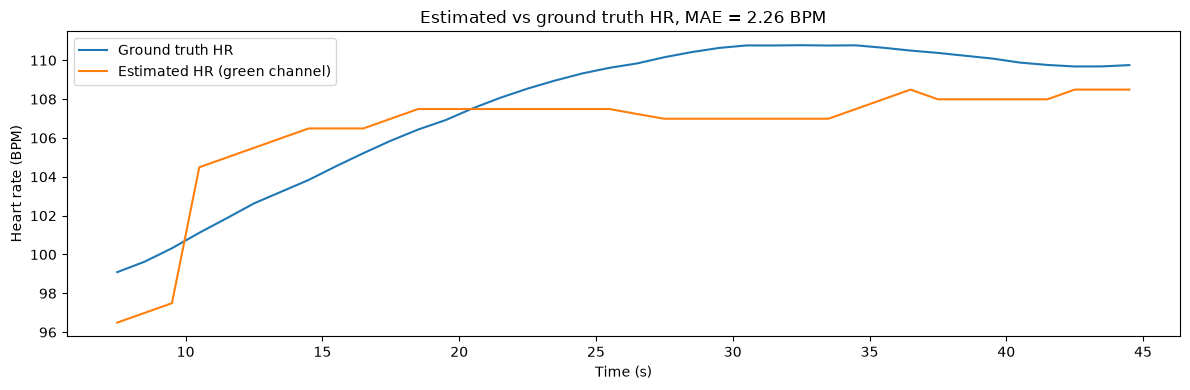

In [7]:
win_sec = 15    # length of each window in seconds
step_sec = 1    # move the window forward by 1 second each time

t = df_full_fixed["time_s"].values
g_clean = keep_heart_waves(df_full_fixed["combined_G"].values, fs)

centers, est_hr, true_hr = [], [], []
start = 0.0
while start + win_sec <= t[-1]:
    # video samples inside this window
    m_vid = (t >= start) & (t < start + win_sec)
    bpm_w, _, _ = find_bpm(g_clean[m_vid], fs)

    # ground truth heart rates inside the same window
    m_gt = (gt["time"] >= start) & (gt["time"] < start + win_sec)

    centers.append(start + win_sec / 2)
    est_hr.append(bpm_w)
    true_hr.append(gt["hr"][m_gt].mean())
    start += step_sec

centers = np.array(centers)
est_hr = np.array(est_hr)
true_hr = np.array(true_hr)
err = np.abs(est_hr - true_hr)

print(f"Windows: {len(centers)} (each {win_sec}s, step {step_sec}s)")
print(f"MAE: {err.mean():.2f} BPM")
print(f"Max error: {err.max():.2f} BPM")
print(f"Windows with error > 5 BPM: {(err > 5).sum()} of {len(err)}")

plt.figure(figsize=(12, 4))
plt.plot(centers, true_hr, label="Ground truth HR")
plt.plot(centers, est_hr, label="Estimated HR (green channel)")
plt.xlabel("Time (s)")
plt.ylabel("Heart rate (BPM)")
plt.title(f"Estimated vs ground truth HR, MAE = {err.mean():.2f} BPM")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
import os

for s in ["subject1", "subject3", "subject8"]:
    p = os.path.join("DATASET_2", s)
    print(s, os.listdir(p) if os.path.exists(p) else "NOT FOUND")
    

subject1 ['ground_truth.txt', 'vid.avi']
subject3 ['ground_truth.txt', 'vid.avi']
subject8 ['ground_truth.txt', 'vid.avi']


In [9]:
import os

def run_subject(subject_dir, win_sec=15, step_sec=1):
    video_path = os.path.join(subject_dir, "vid.avi")
    gt_path = os.path.join(subject_dir, "ground_truth.txt")

    info = inspect_video(video_path)
    fs = info["fps"]
    gt = load_ground_truth(gt_path)
    df = extract_rgb_v2(video_path, max_frames=None, mode="fixed")

    t = df["time_s"].values
    g_clean = keep_heart_waves(df["combined_G"].values, fs)

    est_hr, true_hr = [], []
    start = 0.0
    while start + win_sec <= t[-1]:
        m_vid = (t >= start) & (t < start + win_sec)
        bpm_w, _, _ = find_bpm(g_clean[m_vid], fs)

        m_gt = (gt["time"] >= start) & (gt["time"] < start + win_sec)
        est_hr.append(bpm_w)
        true_hr.append(gt["hr"][m_gt].mean())
        start += step_sec

    est_hr = np.array(est_hr)
    true_hr = np.array(true_hr)
    err = np.abs(est_hr - true_hr)

    return {
        "windows": len(err),
        "mae": err.mean(),
        "max_error": err.max(),
        "bad_windows_over_5": int((err > 5).sum()),
        "gt_mean_hr": gt["hr"].mean(),
    }

# Find every subject folder that has a video
root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))
print("Subjects found:", subjects)

results = []
for s in subjects:
    print(f"\n===== {s} =====")
    try:
        r = run_subject(os.path.join(root, s))
        r["subject"] = s
        r["status"] = "ok"
    except Exception as e:
        print(f"FAILED: {e}")
        r = {"subject": s, "status": f"failed: {e}"}
    results.append(r)

res = pd.DataFrame(results).set_index("subject")
os.makedirs("outputs", exist_ok=True)
res.to_csv("outputs/results_all_subjects.csv")
display(res.round(2))
print("\nMean MAE over successful subjects:", round(res["mae"].mean(), 2), "BPM")

Subjects found: ['subject1', 'subject3', 'subject8']

===== subject1 =====
[GT] raw shape: (3, 1547)
[GT] samples: 1547
[GT] time range: 0.00s -> 52.69s
[GT] average sampling frequency: 29.34 Hz
[GT] HR min/mean/max: 97.0 / 106.7 / 113.0 BPM
[fixed] frames: 1547, rejected detections: 0, start box: [286. 184. 147. 147.]

===== subject3 =====
[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]

===== subject8 =====
[GT] raw shape: (3, 2022)
[GT] samples: 2022
[GT] time range: 0.00s -> 67.64s
[GT] average sampling frequency: 29.88 Hz
[GT] HR min/mean/max: 97.0 / 111.2 / 118.0 BPM
[fixed] frames: 2022, rejected detections: 0, start box: [313.5 173.  186.  186. ]


,windows,mae,max_error,bad_windows_over_5,gt_mean_hr,status
subject,,,,,,
subject1,38,2.26,3.79,0,106.70,ok
subject3,46,12.54,22.17,40,101.17,ok
subject8,53,3.19,60.69,3,111.24,ok



Mean MAE over successful subjects: 6.0 BPM


[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]


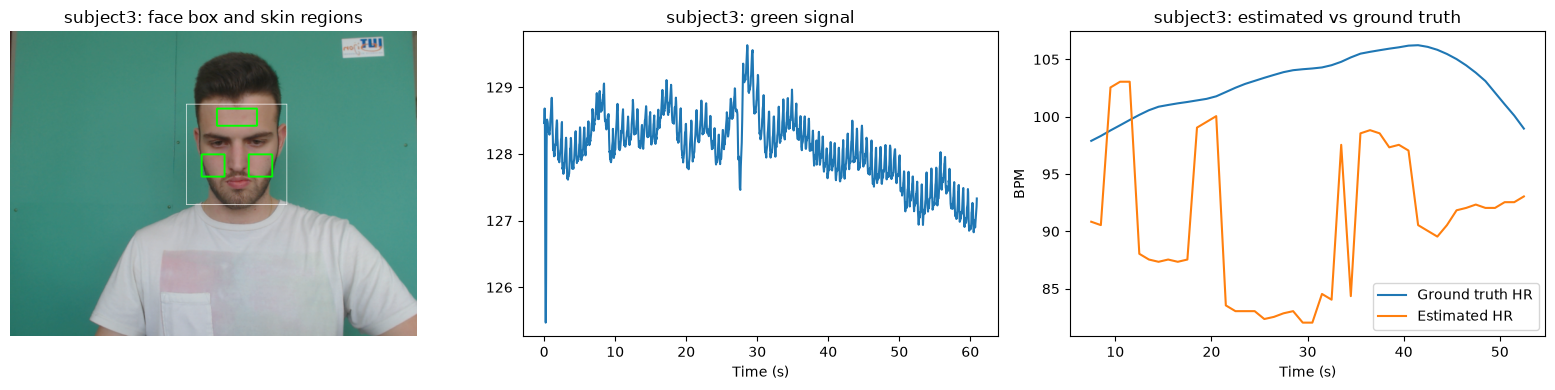

[GT] raw shape: (3, 2022)
[GT] samples: 2022
[GT] time range: 0.00s -> 67.64s
[GT] average sampling frequency: 29.88 Hz
[GT] HR min/mean/max: 97.0 / 111.2 / 118.0 BPM
[fixed] frames: 2022, rejected detections: 0, start box: [313.5 173.  186.  186. ]


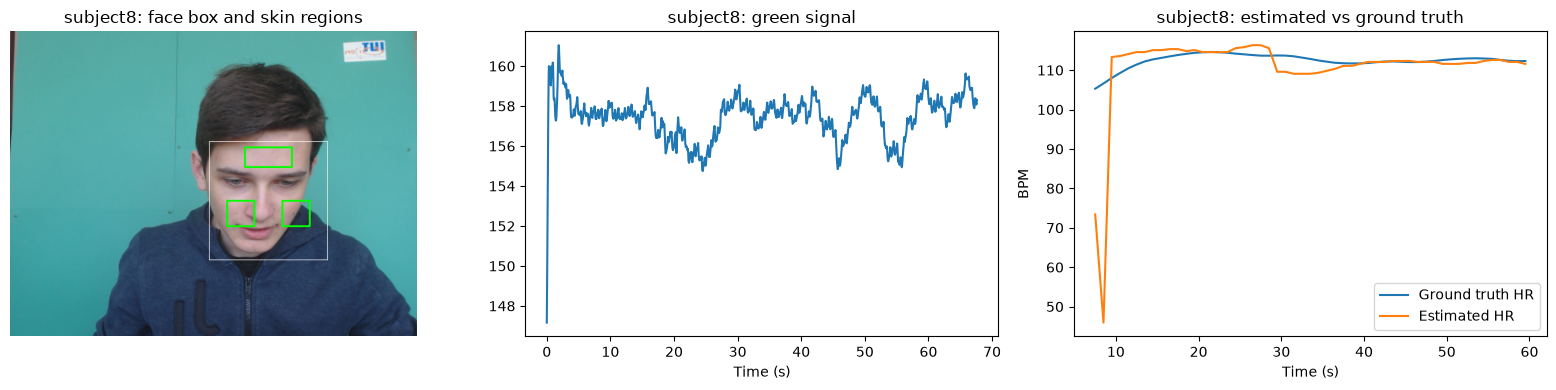

In [10]:
def get_windows(subject_dir, win_sec=15, step_sec=1):
    video_path = os.path.join(subject_dir, "vid.avi")
    gt = load_ground_truth(os.path.join(subject_dir, "ground_truth.txt"))
    fs = inspect_video(video_path)["fps"]
    df = extract_rgb_v2(video_path, max_frames=None, mode="fixed")
    t = df["time_s"].values
    g_clean = keep_heart_waves(df["combined_G"].values, fs)

    centers, est, true = [], [], []
    start = 0.0
    while start + win_sec <= t[-1]:
        m = (t >= start) & (t < start + win_sec)
        bpm_w, _, _ = find_bpm(g_clean[m], fs)
        m_gt = (gt["time"] >= start) & (gt["time"] < start + win_sec)
        centers.append(start + win_sec / 2)
        est.append(bpm_w)
        true.append(gt["hr"][m_gt].mean())
        start += step_sec
    return df, np.array(centers), np.array(est), np.array(true)

def show_roi(subject_dir, n_init=30):
    # Same starting box as extract_rgb_v2: median of the first detections
    cap = cv2.VideoCapture(os.path.join(subject_dir, "vid.avi"))
    dets, first = [], None
    for i in range(n_init):
        ok, f = cap.read()
        if not ok:
            break
        if first is None:
            first = f.copy()
        b = detect_face_box(f)
        if b is not None:
            dets.append(b)
    cap.release()
    box = np.median(np.array(dets, dtype=float), axis=0)
    h_img, w_img = first.shape[:2]
    x, y, w, h = [int(v) for v in box]
    cv2.rectangle(first, (x, y), (x + w, y + h), (255, 255, 255), 1)
    for name, (x1, y1, x2, y2) in skin_regions_from_box(box, w_img, h_img).items():
        cv2.rectangle(first, (x1, y1), (x2, y2), (0, 255, 0), 2)
    return cv2.cvtColor(first, cv2.COLOR_BGR2RGB)

for s in ["subject3", "subject8"]:
    d = os.path.join("DATASET_2", s)
    df_s, centers, est, true = get_windows(d)

    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].imshow(show_roi(d))
    ax[0].set_title(f"{s}: face box and skin regions")
    ax[0].axis("off")
    ax[1].plot(df_s["time_s"], df_s["combined_G"])
    ax[1].set_title(f"{s}: green signal")
    ax[1].set_xlabel("Time (s)")
    ax[2].plot(centers, true, label="Ground truth HR")
    ax[2].plot(centers, est, label="Estimated HR")
    ax[2].set_title(f"{s}: estimated vs ground truth")
    ax[2].set_xlabel("Time (s)")
    ax[2].set_ylabel("BPM")
    ax[2].legend()
    plt.tight_layout()
    plt.show()

[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]


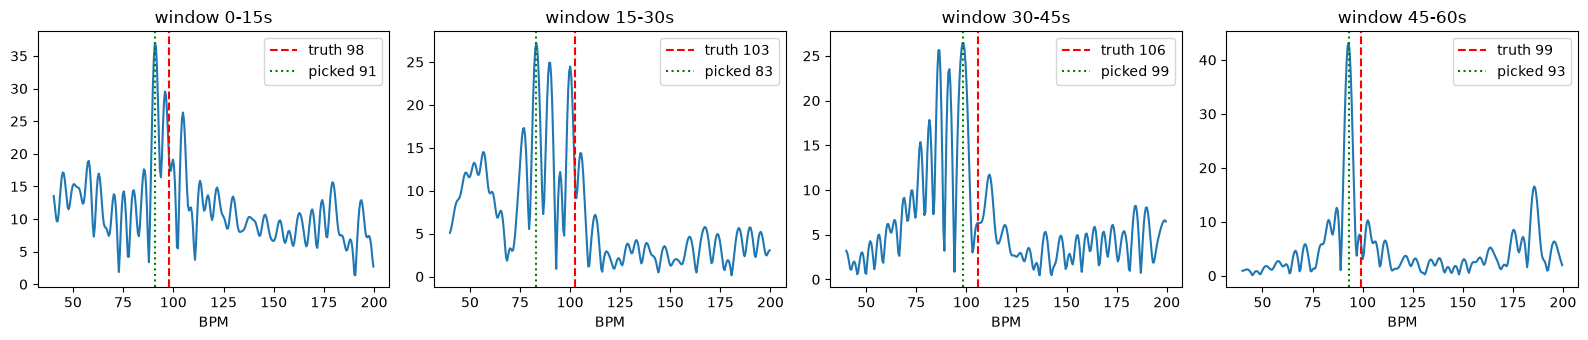

[GT] raw shape: (3, 2022)
[GT] samples: 2022
[GT] time range: 0.00s -> 67.64s
[GT] average sampling frequency: 29.88 Hz
[GT] HR min/mean/max: 97.0 / 111.2 / 118.0 BPM
[fixed] frames: 2022, rejected detections: 0, start box: [313.5 173.  186.  186. ]
window centre 7.5s: estimated 73.4, truth 105.3
window centre 8.5s: estimated 45.9, truth 106.6
window centre 9.5s: estimated 113.3, truth 108.0
window centre 10.5s: estimated 113.6, truth 109.3
window centre 11.5s: estimated 114.1, truth 110.5


In [11]:
def show_spectra(subject_dir, starts, win_sec=15):
    video_path = os.path.join(subject_dir, "vid.avi")
    gt = load_ground_truth(os.path.join(subject_dir, "ground_truth.txt"))
    fs = inspect_video(video_path)["fps"]
    df = extract_rgb_v2(video_path, max_frames=None, mode="fixed")
    t = df["time_s"].values
    g_clean = keep_heart_waves(df["combined_G"].values, fs)

    fig, axes = plt.subplots(1, len(starts), figsize=(4 * len(starts), 3.5))
    for ax, s0 in zip(axes, starts):
        m = (t >= s0) & (t < s0 + win_sec)
        bpm_w, freqs, power = find_bpm(g_clean[m], fs)
        m_gt = (gt["time"] >= s0) & (gt["time"] < s0 + win_sec)
        truth = gt["hr"][m_gt].mean()
        k = (freqs * 60 >= 40) & (freqs * 60 <= 200)
        ax.plot(freqs[k] * 60, power[k])
        ax.axvline(truth, color="red", linestyle="--", label=f"truth {truth:.0f}")
        ax.axvline(bpm_w, color="green", linestyle=":", label=f"picked {bpm_w:.0f}")
        ax.set_title(f"window {s0:.0f}-{s0 + win_sec:.0f}s")
        ax.set_xlabel("BPM")
        ax.legend()
    plt.tight_layout()
    plt.show()

# Check 1: subject3, four windows
show_spectra("DATASET_2/subject3", starts=[0, 15, 30, 45])

# Check 2: subject8, first five windows
_, c8, e8, t8 = get_windows("DATASET_2/subject8")
for c, e, tr in list(zip(c8, e8, t8))[:5]:
    print(f"window centre {c:.1f}s: estimated {e:.1f}, truth {tr:.1f}")

In [12]:
def pos_signal(rgb, fs, win_sec=1.6):
    # rgb: array of shape (N, 3) with the mean R, G, B of every frame
    N = len(rgb)
    L = int(win_sec * fs)
    H = np.zeros(N)
    P = np.array([[0, 1, -1], [-2, 1, 1]])
    for n in range(L - 1, N):
        m = n - L + 1
        C = rgb[m:n + 1].T                       # shape (3, L)
        Cn = C / C.mean(axis=1, keepdims=True)   # divide each color by its own average
        S = P @ Cn
        h = S[0] + (S[0].std() / (S[1].std() + 1e-9)) * S[1]
        H[m:n + 1] += h - h.mean()
    return H

def evaluate(df, gt, fs, method, skip_sec, win_sec=15, step_sec=1):
    t = df["time_s"].values
    if method == "green":
        sig = df["combined_G"].values
    else:
        sig = pos_signal(df[["combined_R", "combined_G", "combined_B"]].values, fs)
    sig = keep_heart_waves(sig, fs)

    errs = []
    start = skip_sec
    while start + win_sec <= t[-1]:
        m = (t >= start) & (t < start + win_sec)
        est, _, _ = find_bpm(sig[m], fs)
        m_gt = (gt["time"] >= start) & (gt["time"] < start + win_sec)
        errs.append(abs(est - gt["hr"][m_gt].mean()))
        start += step_sec
    errs = np.array(errs)
    return errs.mean(), int((errs > 5).sum()), len(errs)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

variants = [("green", 0), ("green", 3), ("pos", 0), ("pos", 3)]
mae_table, bad_table = {}, {}

for s in subjects:
    print(f"\n===== {s} =====")
    d = os.path.join(root, s)
    try:
        fs = inspect_video(os.path.join(d, "vid.avi"))["fps"]
        gt = load_ground_truth(os.path.join(d, "ground_truth.txt"))
        df = extract_rgb_v2(os.path.join(d, "vid.avi"), max_frames=None, mode="fixed")
        mae_row, bad_row = {}, {}
        for method, skip in variants:
            name = f"{method}, skip {skip}s"
            mae, bad, total = evaluate(df, gt, fs, method, skip)
            mae_row[name] = round(mae, 2)
            bad_row[name] = f"{bad}/{total}"
        mae_table[s], bad_table[s] = mae_row, bad_row
    except Exception as e:
        print(f"FAILED: {e}")

mae_df = pd.DataFrame(mae_table).T
print("\nMAE (BPM), lower is better:")
display(mae_df)
print("\nWindows more than 5 BPM wrong:")
display(pd.DataFrame(bad_table).T)
print("\nAverage MAE over subjects:")
print(mae_df.mean().round(2))


===== subject1 =====
[GT] raw shape: (3, 1547)
[GT] samples: 1547
[GT] time range: 0.00s -> 52.69s
[GT] average sampling frequency: 29.34 Hz
[GT] HR min/mean/max: 97.0 / 106.7 / 113.0 BPM
[fixed] frames: 1547, rejected detections: 0, start box: [286. 184. 147. 147.]

===== subject3 =====
[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]

===== subject8 =====
[GT] raw shape: (3, 2022)
[GT] samples: 2022
[GT] time range: 0.00s -> 67.64s
[GT] average sampling frequency: 29.88 Hz
[GT] HR min/mean/max: 97.0 / 111.2 / 118.0 BPM
[fixed] frames: 2022, rejected detections: 0, start box: [313.5 173.  186.  186. ]

MAE (BPM), lower is better:


,"green, skip 0s","green, skip 3s","pos, skip 0s","pos, skip 3s"
subject1,2.26,2.22,2.26,2.25
subject3,12.54,12.98,13.08,13.55
subject8,3.19,1.43,1.55,1.44



Windows more than 5 BPM wrong:


,"green, skip 0s","green, skip 3s","pos, skip 0s","pos, skip 3s"
subject1,0/38,0/35,0/38,0/35
subject3,40/46,38/43,40/46,38/43
subject8,3/53,0/50,1/53,0/50



Average MAE over subjects:
green, skip 0s    6.00
green, skip 3s    5.54
pos, skip 0s      5.63
pos, skip 3s      5.75
dtype: float64


In [13]:
cache = {}

def load_subject(s):
    if s not in cache:
        d = os.path.join("DATASET_2", s)
        fs = inspect_video(os.path.join(d, "vid.avi"))["fps"]
        gt = load_ground_truth(os.path.join(d, "ground_truth.txt"))
        df = extract_rgb_v2(os.path.join(d, "vid.avi"), max_frames=None, mode="fixed")
        cache[s] = (df, gt, fs)
    return cache[s]

def window_errors(sig, t, hr_t, hr, fs, skip_sec=3, win_sec=15, step_sec=1):
    sig = keep_heart_waves(sig, fs)
    errs = []
    start = skip_sec
    while start + win_sec <= t[-1]:
        m = (t >= start) & (t < start + win_sec)
        est, _, _ = find_bpm(sig[m], fs)
        m_gt = (hr_t >= start) & (hr_t < start + win_sec)
        errs.append(abs(est - hr[m_gt].mean()))
        start += step_sec
    return np.array(errs)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

region_rows, gt_rows = {}, {}
for s in subjects:
    print(f"\n===== {s} =====")
    df, gt, fs = load_subject(s)
    t = df["time_s"].values

    # Check B: one face area at a time (green channel)
    row = {}
    for name, col in [("forehead", "forehead_G"), ("left cheek", "left_cheek_G"),
                      ("right cheek", "right_cheek_G"), ("all combined", "combined_G")]:
        e = window_errors(df[col].values, t, gt["time"], gt["hr"], fs)
        row[name] = round(e.mean(), 2)
    region_rows[s] = row

    # Check A: heart rate found from the ground truth wave vs the ground truth hr numbers
    e = window_errors(gt["ppg"], gt["time"], gt["time"], gt["hr"], gt["fs"])
    gt_rows[s] = {"GT wave vs GT hr numbers (MAE)": round(e.mean(), 2)}

print("\nCheck B: MAE (BPM) by face area, skip 3 s")
display(pd.DataFrame(region_rows).T)
print("\nCheck A: is the ground truth consistent with itself?")
display(pd.DataFrame(gt_rows).T)


===== subject1 =====
[GT] raw shape: (3, 1547)
[GT] samples: 1547
[GT] time range: 0.00s -> 52.69s
[GT] average sampling frequency: 29.34 Hz
[GT] HR min/mean/max: 97.0 / 106.7 / 113.0 BPM
[fixed] frames: 1547, rejected detections: 0, start box: [286. 184. 147. 147.]

===== subject3 =====
[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]

===== subject8 =====
[GT] raw shape: (3, 2022)
[GT] samples: 2022
[GT] time range: 0.00s -> 67.64s
[GT] average sampling frequency: 29.88 Hz
[GT] HR min/mean/max: 97.0 / 111.2 / 118.0 BPM
[fixed] frames: 2022, rejected detections: 0, start box: [313.5 173.  186.  186. ]

Check B: MAE (BPM) by face area, skip 3 s


,forehead,left cheek,right cheek,all combined
subject1,2.21,2.24,2.20,2.22
subject3,15.26,16.88,14.29,12.98
subject8,19.32,1.42,28.29,1.43



Check A: is the ground truth consistent with itself?


,GT wave vs GT hr numbers (MAE)
subject1,2.13
subject3,10.01
subject8,1.41


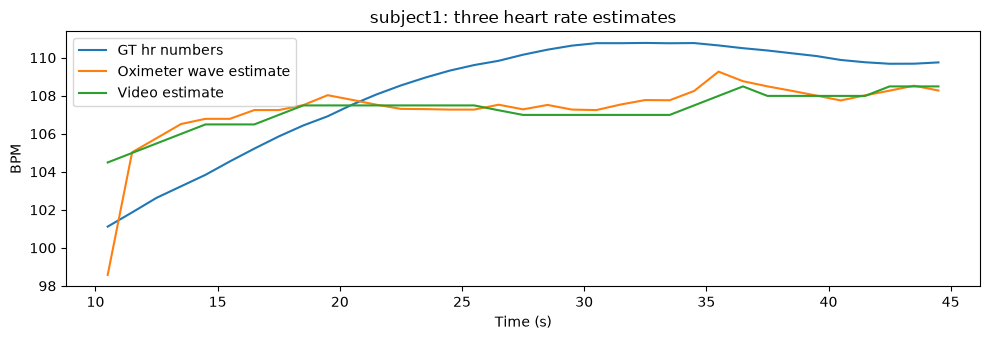

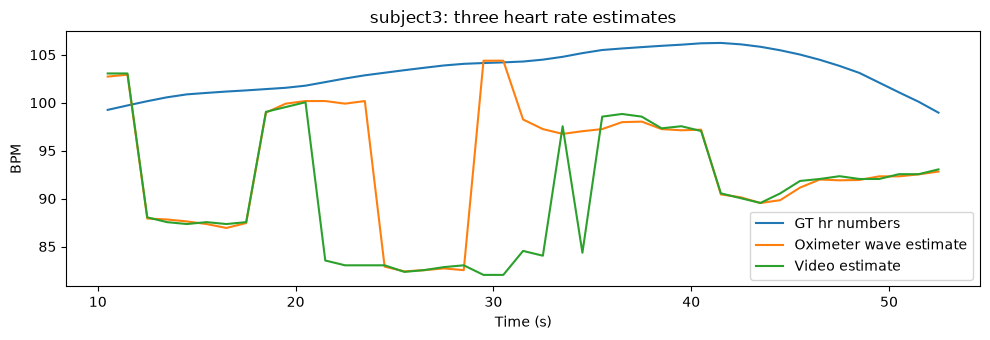

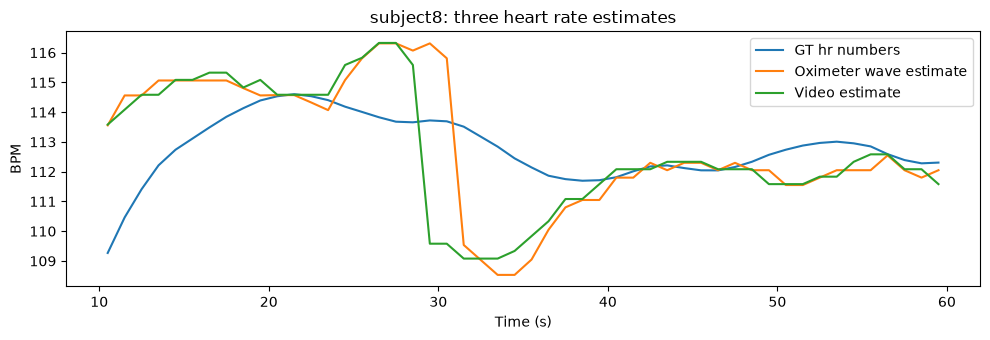

MAE (BPM) between the three estimates:


,video vs hr numbers,video vs oximeter wave,oximeter wave vs hr numbers
subject1,2.22,0.50,2.13
subject3,12.98,3.38,10.01
subject8,1.43,0.49,1.41


In [14]:
def window_estimates(sig, t, fs, skip_sec=3, win_sec=15, step_sec=1):
    sig = keep_heart_waves(sig, fs)
    centers, est = [], []
    start = skip_sec
    while start + win_sec <= t[-1]:
        m = (t >= start) & (t < start + win_sec)
        e, _, _ = find_bpm(sig[m], fs)
        centers.append(start + win_sec / 2)
        est.append(e)
        start += step_sec
    return np.array(centers), np.array(est)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

rows = {}
for s in subjects:
    df, gt, fs = load_subject(s)

    c_vid, est_vid = window_estimates(df["combined_G"].values, df["time_s"].values, fs)
    c_wav, est_wav = window_estimates(gt["ppg"], gt["time"], gt["fs"])

    n = min(len(c_vid), len(c_wav))
    c, est_vid, est_wav = c_vid[:n], est_vid[:n], est_wav[:n]

    hr_nums = np.array([
        gt["hr"][(gt["time"] >= ci - 7.5) & (gt["time"] < ci + 7.5)].mean()
        for ci in c])

    rows[s] = {
        "video vs hr numbers": round(np.abs(est_vid - hr_nums).mean(), 2),
        "video vs oximeter wave": round(np.abs(est_vid - est_wav).mean(), 2),
        "oximeter wave vs hr numbers": round(np.abs(est_wav - hr_nums).mean(), 2),
    }

    plt.figure(figsize=(10, 3.5))
    plt.plot(c, hr_nums, label="GT hr numbers")
    plt.plot(c, est_wav, label="Oximeter wave estimate")
    plt.plot(c, est_vid, label="Video estimate")
    plt.title(f"{s}: three heart rate estimates")
    plt.xlabel("Time (s)")
    plt.ylabel("BPM")
    plt.legend()
    plt.tight_layout()
    plt.show()

print("MAE (BPM) between the three estimates:")
display(pd.DataFrame(rows).T)

In [15]:
from scipy.signal import find_peaks

def bpm_by_peaks(x, fs):
    # Count heartbeats directly: find the peaks, then use the average gap between them
    x = x - np.mean(x)
    peaks, _ = find_peaks(x, distance=int(fs * 60 / 200), prominence=0.3 * np.std(x))
    if len(peaks) < 3:
        return np.nan
    return 60.0 * (len(peaks) - 1) / ((peaks[-1] - peaks[0]) / fs)

def eval_est(sig, t_sig, fs_sig, hr_t, hr, method, win_sec, skip_sec=3, step_sec=1):
    sig = keep_heart_waves(sig, fs_sig)
    errs = []
    start = skip_sec
    while start + win_sec <= t_sig[-1]:
        m = (t_sig >= start) & (t_sig < start + win_sec)
        if method == "fft":
            est, _, _ = find_bpm(sig[m], fs_sig)
        else:
            est = bpm_by_peaks(sig[m], fs_sig)
        m_gt = (hr_t >= start) & (hr_t < start + win_sec)
        errs.append(abs(est - hr[m_gt].mean()))
        start += step_sec
    return np.nanmean(errs)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

settings = [("fft", 15), ("fft", 30), ("peaks", 15), ("peaks", 30)]
video_rows, wave_rows = {}, {}

for s in subjects:
    df, gt, fs = load_subject(s)
    v_row, w_row = {}, {}
    for method, win in settings:
        name = f"{method} {win}s"
        v_row[name] = round(eval_est(df["combined_G"].values, df["time_s"].values, fs,
                                     gt["time"], gt["hr"], method, win), 2)
        w_row[name] = round(eval_est(gt["ppg"], gt["time"], gt["fs"],
                                     gt["time"], gt["hr"], method, win), 2)
    video_rows[s], wave_rows[s] = v_row, w_row

print("VIDEO signal vs GT hr numbers, MAE (BPM):")
display(pd.DataFrame(video_rows).T)
print("\nOXIMETER WAVE vs GT hr numbers, MAE (BPM):")
display(pd.DataFrame(wave_rows).T)

VIDEO signal vs GT hr numbers, MAE (BPM):


,fft 15s,fft 30s,peaks 15s,peaks 30s
subject1,2.22,1.51,2.24,1.34
subject3,12.98,13.24,7.57,7.88
subject8,1.43,1.44,1.51,1.10



OXIMETER WAVE vs GT hr numbers, MAE (BPM):


,fft 15s,fft 30s,peaks 15s,peaks 30s
subject1,2.13,1.35,2.09,1.12
subject3,10.01,9.36,6.76,6.12
subject8,1.41,1.45,1.44,1.11


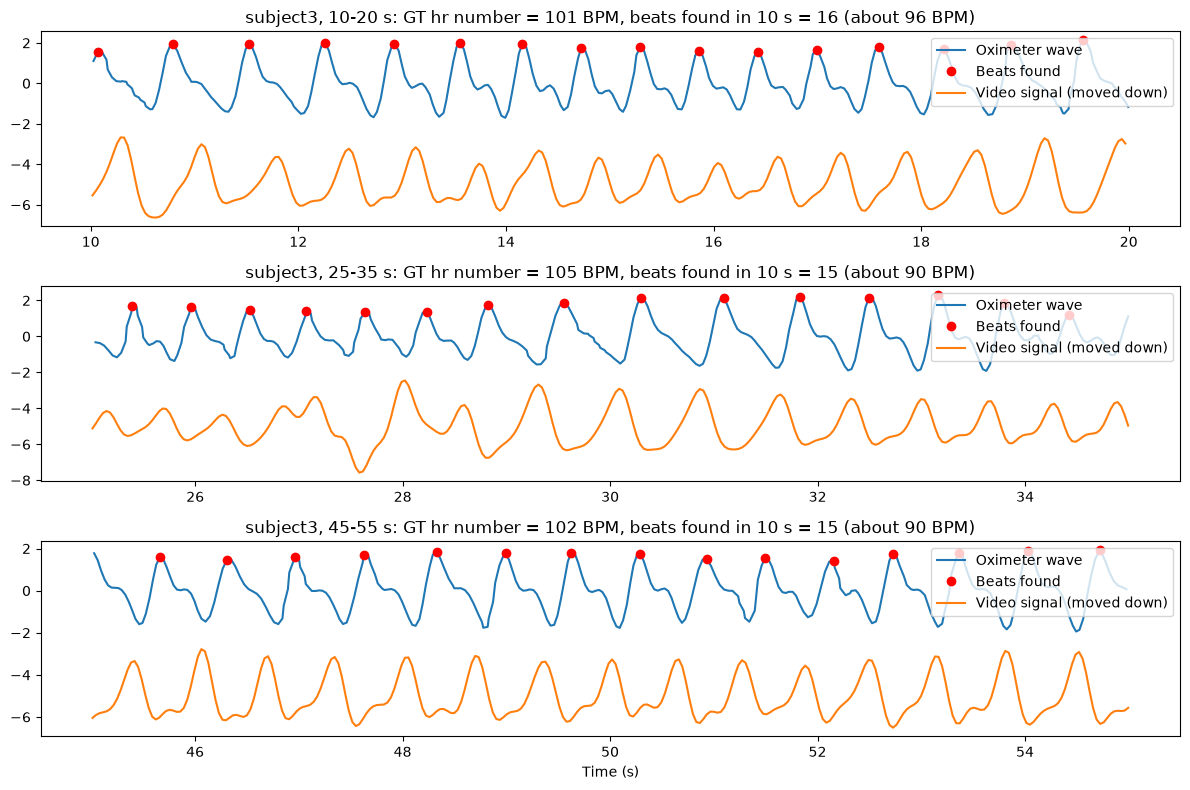

In [16]:
s = "subject3"
df, gt, fs = load_subject(s)

ppg_f = keep_heart_waves(gt["ppg"], gt["fs"])
vid_f = keep_heart_waves(df["combined_G"].values, fs)

def segment(sig, t, a, b):
    m = (t >= a) & (t < b)
    return t[m], sig[m]

fig, axes = plt.subplots(3, 1, figsize=(12, 8))
for ax, a in zip(axes, [10, 25, 45]):
    tw, w = segment(ppg_f, gt["time"], a, a + 10)
    tv, v = segment(vid_f, df["time_s"].values, a, a + 10)
    w = w / np.std(w)
    v = v / np.std(v)

    peaks, _ = find_peaks(w, distance=int(gt["fs"] * 60 / 200), prominence=0.3)
    m_gt = (gt["time"] >= a) & (gt["time"] < a + 10)
    hr_number = gt["hr"][m_gt].mean()

    ax.plot(tw, w, label="Oximeter wave")
    ax.plot(tw[peaks], w[peaks], "ro", label="Beats found")
    ax.plot(tv, v - 5, label="Video signal (moved down)")
    ax.set_title(f"{s}, {a}-{a + 10} s: GT hr number = {hr_number:.0f} BPM, "
                 f"beats found in 10 s = {len(peaks)} (about {len(peaks) * 6} BPM)")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [17]:
def peak_rate(x_filtered, fs):
    x = x_filtered - np.mean(x_filtered)
    peaks, _ = find_peaks(x, distance=int(fs * 60 / 200), prominence=0.3 * np.std(x))
    if len(peaks) < 3:
        return np.nan
    return 60.0 * (len(peaks) - 1) / ((peaks[-1] - peaks[0]) / fs)

def count_beats(x_filtered, fs):
    x = x_filtered - np.mean(x_filtered)
    peaks, _ = find_peaks(x, distance=int(fs * 60 / 200), prominence=0.3 * np.std(x))
    return len(peaks)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

rows = {}
for s in subjects:
    df, gt, fs = load_subject(s)
    t_v = df["time_s"].values
    v = keep_heart_waves(df["combined_G"].values, fs)
    w = keep_heart_waves(gt["ppg"], gt["fs"])
    mv = t_v >= 3
    mw = gt["time"] >= 3
    rows[s] = {
        "hr numbers (mean)": round(gt["hr"][mw].mean(), 1),
        "oximeter wave (peak count)": round(peak_rate(w[mw], gt["fs"]), 1),
        "video (peak count)": round(peak_rate(v[mv], fs), 1),
    }

res = pd.DataFrame(rows).T
res["wave minus hr numbers"] = (res["oximeter wave (peak count)"] - res["hr numbers (mean)"]).round(1)
res["video minus hr numbers"] = (res["video (peak count)"] - res["hr numbers (mean)"]).round(1)
print("Whole-video average heart rate (BPM), skipping the first 3 s:")
display(res)

# Subject3 in 10 s steps
s = "subject3"
df, gt, fs = load_subject(s)
t_v = df["time_s"].values
v = keep_heart_waves(df["combined_G"].values, fs)
w = keep_heart_waves(gt["ppg"], gt["fs"])

steps = []
a = 3
while a + 10 <= gt["time"][-1]:
    mw = (gt["time"] >= a) & (gt["time"] < a + 10)
    mv = (t_v >= a) & (t_v < a + 10)
    steps.append({
        "window": f"{a}-{a + 10} s",
        "hr number": round(gt["hr"][mw].mean(), 1),
        "wave beats x 6": count_beats(w[mw], gt["fs"]) * 6,
        "video beats x 6": count_beats(v[mv], fs) * 6,
    })
    a += 10
print("\nsubject3 in 10 s steps:")
display(pd.DataFrame(steps))

Whole-video average heart rate (BPM), skipping the first 3 s:


,hr numbers (mean),oximeter wave (peak count),video (peak count),wave minus hr numbers,video minus hr numbers
subject1,107.3,106.7,106.3,-0.6,-1.0
subject3,101.5,97.0,95.4,-4.5,-6.1
subject8,111.9,111.9,112.5,0.0,0.6



subject3 in 10 s steps:


,window,hr number,wave beats x 6,video beats x 6
0,3-13 s,98.3,96,96
1,13-23 s,101.5,90,96
2,23-33 s,104.1,96,90
3,33-43 s,105.3,114,102
4,43-53 s,104.5,90,90


In [19]:
def eval_vs_refs(s, method, win_sec=30, skip_sec=3, step_sec=1):
    df, gt, fs = load_subject(s)
    t_v = df["time_s"].values
    v = keep_heart_waves(df["combined_G"].values, fs)
    w = keep_heart_waves(gt["ppg"], gt["fs"])

    err_hr, err_wave = [], []
    a = skip_sec
    while a + win_sec <= min(t_v[-1], gt["time"][-1]):
        mv = (t_v >= a) & (t_v < a + win_sec)
        mw = (gt["time"] >= a) & (gt["time"] < a + win_sec)

        if method == "fft":
            est, _, _ = find_bpm(v[mv], fs)
        else:
            est = peak_rate(v[mv], fs)

        ref_hr = gt["hr"][mw].mean()         # reference 1: hr numbers in the file
        ref_wave = peak_rate(w[mw], gt["fs"])  # reference 2: beats counted on the oximeter wave

        err_hr.append(abs(est - ref_hr))
        err_wave.append(abs(est - ref_wave))
        a += step_sec
    return np.nanmean(err_hr), np.nanmean(err_wave)

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

rows = {}
for s in subjects:
    row = {}
    for method in ["peaks", "fft"]:
        e_hr, e_wave = eval_vs_refs(s, method)
        row[f"{method} vs hr numbers"] = round(e_hr, 2)
        row[f"{method} vs oximeter wave"] = round(e_wave, 2)
    rows[s] = row

table = pd.DataFrame(rows).T
print("MAE (BPM), 30 s windows, skipping the first 3 s:")
display(table)
print("\nAverage over subjects:")
print(table.mean().round(2))

MAE (BPM), 30 s windows, skipping the first 3 s:


,peaks vs hr numbers,peaks vs oximeter wave,fft vs hr numbers,fft vs oximeter wave
subject1,1.34,0.33,1.51,0.39
subject3,7.88,1.77,13.24,7.24
subject8,1.10,0.17,1.44,1.23



Average over subjects:
peaks vs hr numbers       3.44
peaks vs oximeter wave    0.76
fft vs hr numbers         5.40
fft vs oximeter wave      2.95
dtype: float64


In [20]:
s = "subject3"
d = os.path.join("DATASET_2", s)

show_roi(d)

array([[[ 51,  30,  29],
        [ 52,  31,  30],
        [ 65,  49,  42],
        ...,
        [ 89,  86,  68],
        [ 93,  87,  70],
        [ 90,  84,  67]],

       [[ 53,  31,  26],
        [ 54,  32,  27],
        [ 60,  48,  42],
        ...,
        [ 89,  88,  71],
        [ 90,  87,  71],
        [ 90,  87,  71]],

       [[ 55,  31,  24],
        [ 55,  31,  24],
        [ 63,  51,  45],
        ...,
        [ 90,  87,  71],
        [ 90,  87,  71],
        [ 90,  87,  71]],

       ...,

       [[ 35, 113,  98],
        [ 36, 114,  99],
        [ 35, 112, 100],
        ...,
        [177, 142, 121],
        [177, 142, 121],
        [177, 142, 121]],

       [[ 34, 112,  97],
        [ 36, 114,  99],
        [ 35, 113,  98],
        ...,
        [177, 142, 123],
        [177, 142, 121],
        [177, 142, 121]],

       [[ 35, 113,  98],
        [ 35, 113,  98],
        [ 35, 112, 100],
        ...,
        [176, 141, 122],
        [178, 141, 121],
        [177, 140, 120]]

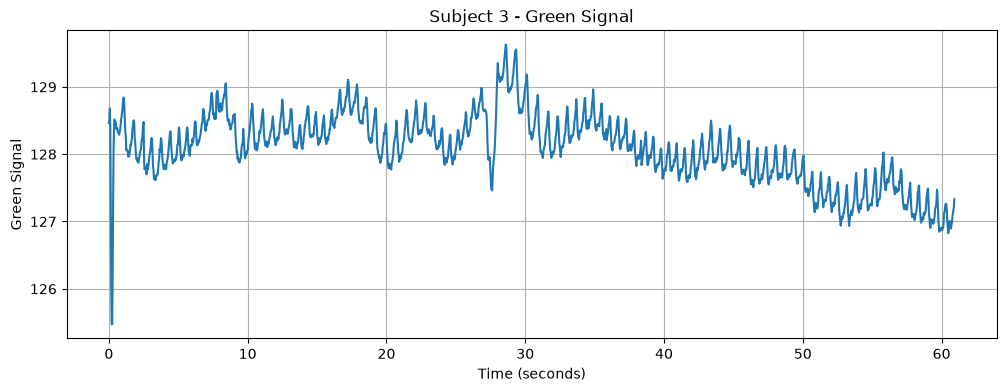

In [21]:
df, gt, fs = load_subject("subject3")

plt.figure(figsize=(12, 4))
plt.plot(df["time_s"], df["combined_G"])

plt.title("Subject 3 - Green Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Green Signal")

plt.grid()
plt.show()

[GT] raw shape: (3, 1801)
[GT] samples: 1801
[GT] time range: 0.00s -> 60.93s
[GT] average sampling frequency: 29.54 Hz
[GT] HR min/mean/max: 92.0 / 101.2 / 108.0 BPM
[fixed] frames: 1801, rejected detections: 0, start box: [277.5 114.  158.5 158.5]


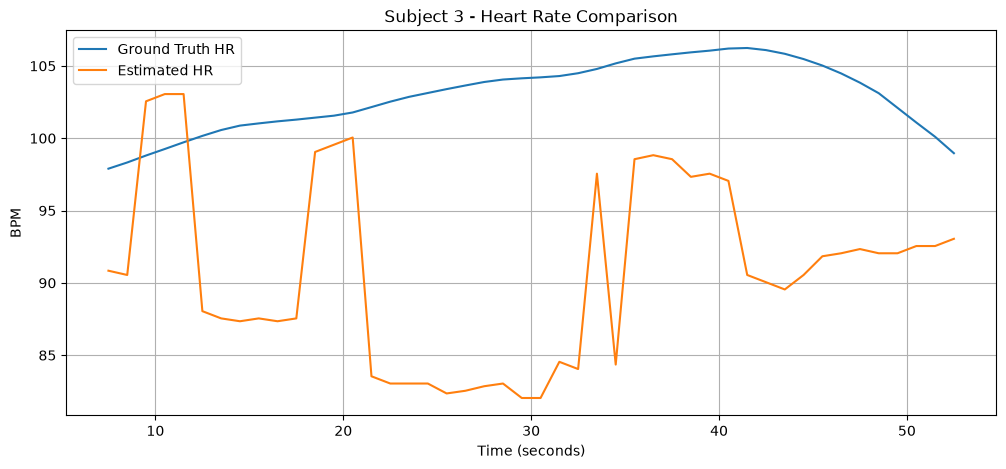

In [22]:
d = os.path.join("DATASET_2", "subject3")

df_s, centers, est, true = get_windows(d)

plt.figure(figsize=(12, 5))

plt.plot(centers, true, label="Ground Truth HR")
plt.plot(centers, est, label="Estimated HR")

plt.title("Subject 3 - Heart Rate Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("BPM")

plt.legend()
plt.grid()
plt.show()

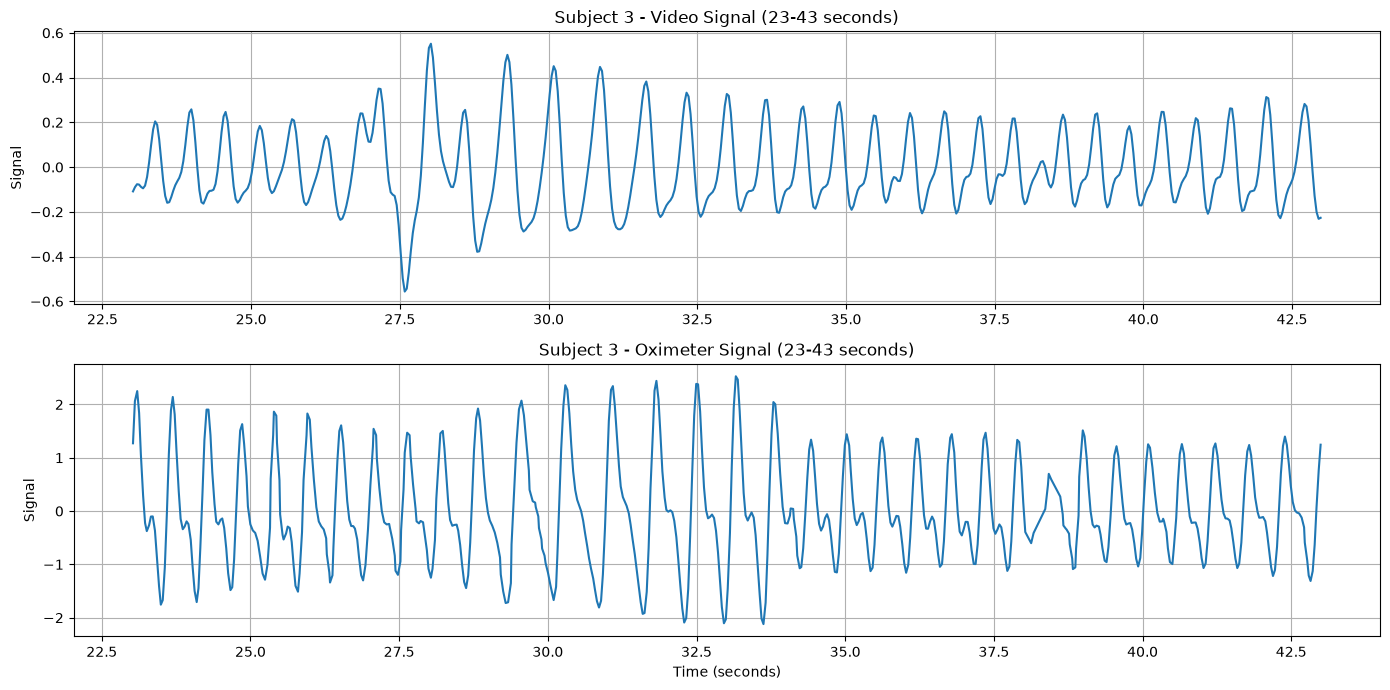

In [24]:
s = "subject3"

df, gt, fs = load_subject(s)

vid = keep_heart_waves(
    df["combined_G"].values, fs
)

ppg = keep_heart_waves(
    gt["ppg"], gt["fs"]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Video signal
t_video = np.asarray(df["time_s"])
m1 = (t_video >= 23) & (t_video <= 43)

axes[0].plot(
    t_video[m1],
    vid[m1]
)

axes[0].set_title("Subject 3 - Video Signal (23-43 seconds)")
axes[0].set_ylabel("Signal")
axes[0].grid()

# Oximeter signal
t_gt = np.asarray(gt["time"])
m2 = (t_gt >= 23) & (t_gt <= 43)

axes[1].plot(
    t_gt[m2],
    ppg[m2]
)

axes[1].set_title("Subject 3 - Oximeter Signal (23-43 seconds)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Signal")
axes[1].grid()

plt.tight_layout()
plt.show()

In [27]:
CONFIG = {"skip_sec": 3, "win_sec": 30, "step_sec": 1}

def run_pipeline(s, cfg=CONFIG):
    df, gt, fs = load_subject(s)
    t_v = df["time_s"].values
    v = keep_heart_waves(df["combined_G"].values, fs)
    w = keep_heart_waves(gt["ppg"], gt["fs"])

    rows = []
    a = cfg["skip_sec"]
    end = min(t_v[-1], gt["time"][-1])
    while a + cfg["win_sec"] <= end:
        mv = (t_v >= a) & (t_v < a + cfg["win_sec"])
        mw = (gt["time"] >= a) & (gt["time"] < a + cfg["win_sec"])
        rows.append({
            "subject": s,
            "start_s": a,
            "video_hr": peak_rate(v[mv], fs),         # nan if fewer than 3 beats found
            "wave_hr": peak_rate(w[mw], gt["fs"]),
            "file_hr": gt["hr"][mw].mean(),
        })
        a += cfg["step_sec"]

    out = pd.DataFrame(rows)
    out["err_vs_wave"] = (out["video_hr"] - out["wave_hr"]).abs()
    out["err_vs_file"] = (out["video_hr"] - out["file_hr"]).abs()
    return out

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

all_windows = pd.concat([run_pipeline(s) for s in subjects], ignore_index=True)

summary = all_windows.groupby("subject").agg(
    windows=("start_s", "count"),
    failed_windows=("video_hr", lambda x: x.isna().sum()),
    mae_vs_wave=("err_vs_wave", "mean"),
    mae_vs_file=("err_vs_file", "mean"),
    over5_vs_wave=("err_vs_wave", lambda x: (x > 5).sum()),
    over5_vs_file=("err_vs_file", lambda x: (x > 5).sum()),
).round(2).reindex(subjects)

os.makedirs("outputs", exist_ok=True)
all_windows.to_csv("outputs/debug_all_windows.csv", index=False)
display(summary)
print("\nAverage over subjects:")
print(summary[["mae_vs_wave", "mae_vs_file"]].mean().round(2))

[GT] raw shape: (3, 2018)
[GT] samples: 2018
[GT] time range: 0.00s -> 67.72s
[GT] average sampling frequency: 29.78 Hz
[GT] HR min/mean/max: 94.0 / 107.1 / 119.0 BPM
[fixed] frames: 2018, rejected detections: 0, start box: [228.  135.5 175.  175. ]
[GT] raw shape: (3, 2032)
[GT] samples: 2032
[GT] time range: 0.00s -> 68.30s
[GT] average sampling frequency: 29.74 Hz
[GT] HR min/mean/max: 89.0 / 101.8 / 111.0 BPM
[fixed] frames: 2032, rejected detections: 0, start box: [252.5 159.  156.  156. ]


,windows,failed_windows,mae_vs_wave,mae_vs_file,over5_vs_wave,over5_vs_file
subject,,,,,,
subject1,20,0,0.33,1.34,0,0
subject3,28,0,1.77,7.88,0,28
subject8,35,0,0.17,1.10,0,0
subject13,35,0,12.48,12.72,29,28
subject22,36,0,16.00,16.07,33,31



Average over subjects:
mae_vs_wave    6.15
mae_vs_file    7.82
dtype: float64


,video mean,wave mean,file mean,video / wave ratio
subject13,120.8,108.4,108.1,1.12
subject22,119.5,103.5,103.4,1.16


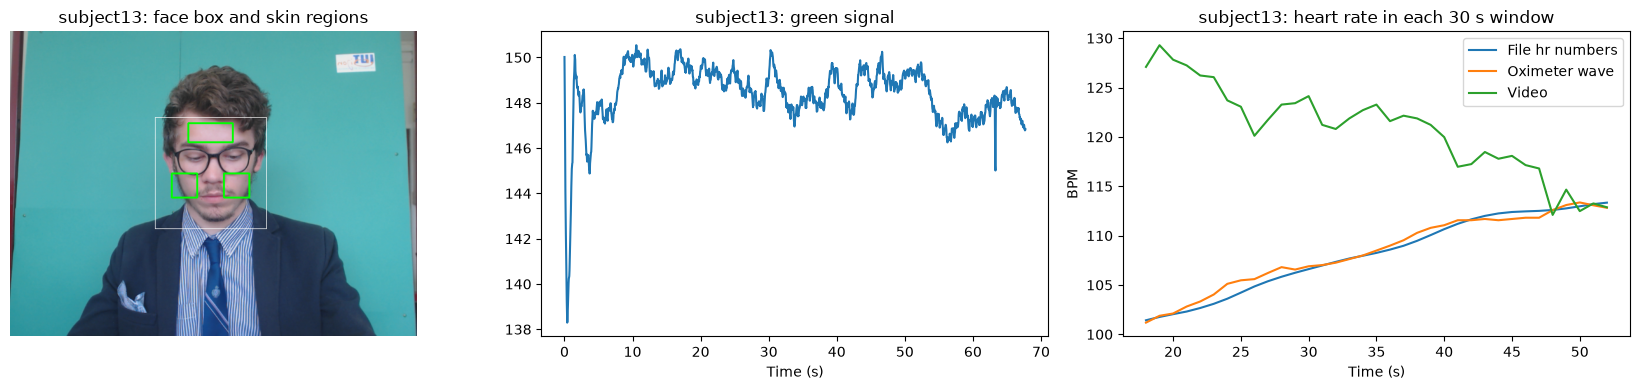

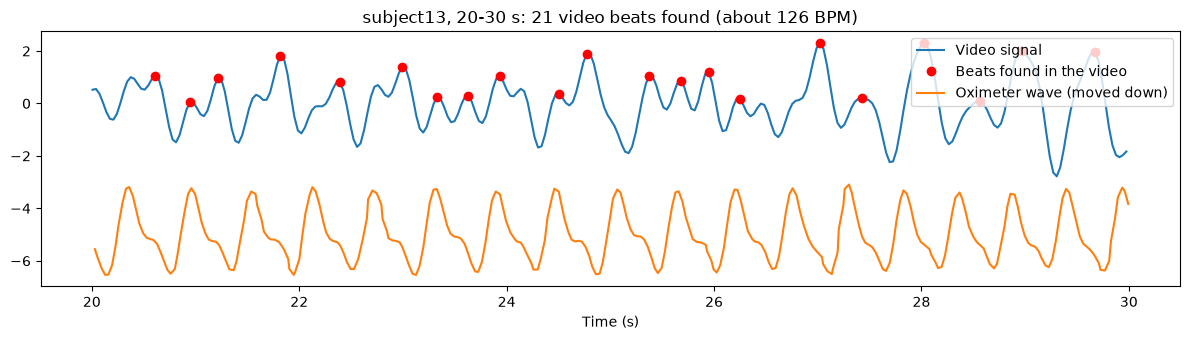

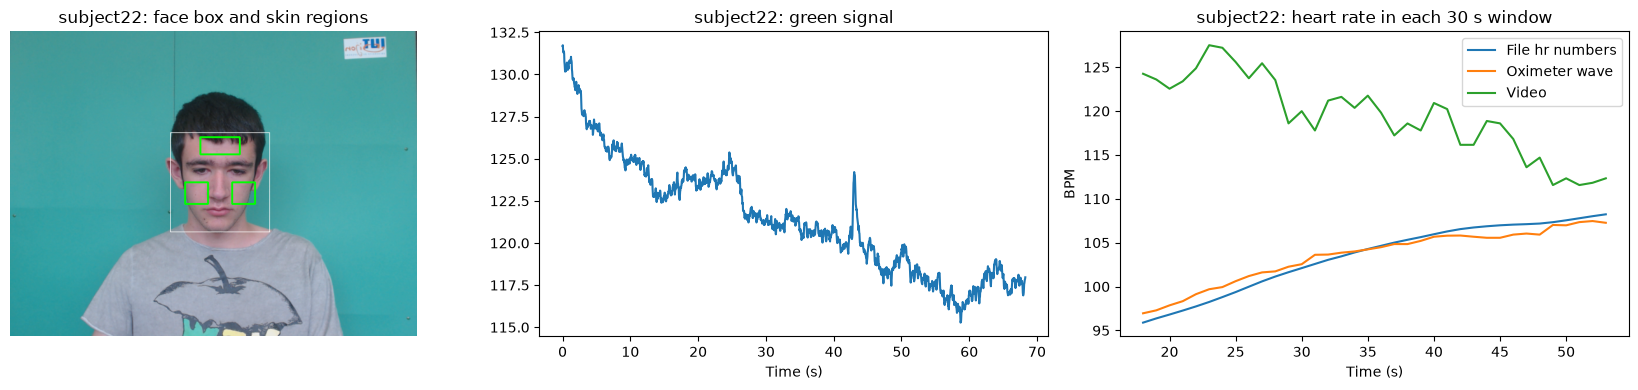

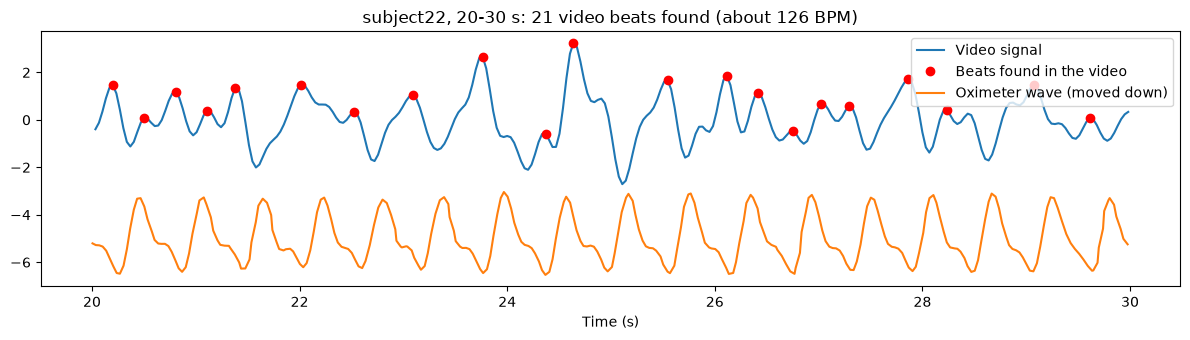

In [28]:
# Part 1: average heart rate from each source, and the ratio video / wave
rows = {}
for s in ["subject13", "subject22"]:
    w = all_windows[all_windows.subject == s]
    rows[s] = {
        "video mean": round(float(w.video_hr.mean()), 1),
        "wave mean": round(float(w.wave_hr.mean()), 1),
        "file mean": round(float(w.file_hr.mean()), 1),
        "video / wave ratio": round(float((w.video_hr / w.wave_hr).mean()), 2),
    }
display(pd.DataFrame(rows).T)

# Part 2: pictures for each subject
for s in ["subject13", "subject22"]:
    d = os.path.join("DATASET_2", s)
    df, gt, fs = load_subject(s)
    w = all_windows[all_windows.subject == s]

    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].imshow(show_roi(d))
    ax[0].axis("off")
    ax[0].set_title(f"{s}: face box and skin regions")
    ax[1].plot(df["time_s"], df["combined_G"])
    ax[1].set_title(f"{s}: green signal")
    ax[1].set_xlabel("Time (s)")
    ax[2].plot(w.start_s + 15, w.file_hr, label="File hr numbers")
    ax[2].plot(w.start_s + 15, w.wave_hr, label="Oximeter wave")
    ax[2].plot(w.start_s + 15, w.video_hr, label="Video")
    ax[2].set_title(f"{s}: heart rate in each 30 s window")
    ax[2].set_xlabel("Time (s)")
    ax[2].set_ylabel("BPM")
    ax[2].legend()
    plt.tight_layout()
    plt.show()

    # 10 seconds of the filtered video signal and the oximeter wave, with the video beats marked
    v = keep_heart_waves(df["combined_G"].values, fs)
    p = keep_heart_waves(gt["ppg"], gt["fs"])
    t_v = df["time_s"].values
    a = 20
    mv = (t_v >= a) & (t_v < a + 10)
    mp = (gt["time"] >= a) & (gt["time"] < a + 10)
    vv = v[mv] / np.std(v[mv])
    pp = p[mp] / np.std(p[mp])
    pk, _ = find_peaks(vv - vv.mean(), distance=int(fs * 60 / 200), prominence=0.3)
    plt.figure(figsize=(12, 3.5))
    plt.plot(t_v[mv], vv, label="Video signal")
    plt.plot(t_v[mv][pk], vv[pk], "ro", label="Beats found in the video")
    plt.plot(gt["time"][mp], pp - 5, label="Oximeter wave (moved down)")
    plt.title(f"{s}, {a}-{a + 10} s: {len(pk)} video beats found (about {len(pk) * 6} BPM)")
    plt.xlabel("Time (s)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

In [29]:
def peak_rate2(x_filtered, fs, prom=0.3):
    x = x_filtered - np.mean(x_filtered)
    peaks, _ = find_peaks(x, distance=int(fs * 60 / 200), prominence=prom * np.std(x))
    if len(peaks) < 3:
        return np.nan
    return 60.0 * (len(peaks) - 1) / ((peaks[-1] - peaks[0]) / fs)

def eval_variant(s, source, hi, method, prom, win_sec=30, skip_sec=3, step_sec=1):
    df, gt, fs = load_subject(s)
    t_v = df["time_s"].values
    if source == "green":
        raw = df["combined_G"].values
    else:
        raw = pos_signal(df[["combined_R", "combined_G", "combined_B"]].values, fs)
    v = keep_heart_waves(raw, fs, high=hi)
    w = keep_heart_waves(gt["ppg"], gt["fs"])       # reference signal stays the same for every variant

    err_wave, err_file = [], []
    a = skip_sec
    end = min(t_v[-1], gt["time"][-1])
    while a + win_sec <= end:
        mv = (t_v >= a) & (t_v < a + win_sec)
        mw = (gt["time"] >= a) & (gt["time"] < a + win_sec)
        if method == "fft":
            est, _, _ = find_bpm(v[mv], fs, 0.7, hi)
        else:
            est = peak_rate2(v[mv], fs, prom)
        ref_wave = peak_rate2(w[mw], gt["fs"], 0.3)  # same reference as before
        ref_file = gt["hr"][mw].mean()
        err_wave.append(abs(est - ref_wave))
        err_file.append(abs(est - ref_file))
        a += step_sec
    return np.nanmean(err_wave), np.nanmean(err_file)

variants = {
    "current (green, 4 Hz, peaks 0.3)": ("green", 4.0, "peaks", 0.3),
    "green, 4 Hz, peaks 0.6":           ("green", 4.0, "peaks", 0.6),
    "green, 3 Hz, peaks 0.6":           ("green", 3.0, "peaks", 0.6),
    "green, 4 Hz, fft":                 ("green", 4.0, "fft", None),
    "pos, 4 Hz, peaks 0.6":             ("pos", 4.0, "peaks", 0.6),
    "pos, 4 Hz, fft":                   ("pos", 4.0, "fft", None),
}

root = "DATASET_2"
subjects = sorted(
    [d for d in os.listdir(root)
     if d.startswith("subject")
     and os.path.exists(os.path.join(root, d, "vid.avi"))],
    key=lambda s: int(s.replace("subject", "")))

wave_tab, file_tab = {}, {}
for s in subjects:
    wave_tab[s], file_tab[s] = {}, {}
    for name, (source, hi, method, prom) in variants.items():
        e_w, e_f = eval_variant(s, source, hi, method, prom)
        wave_tab[s][name] = round(e_w, 2)
        file_tab[s][name] = round(e_f, 2)

wave_df = pd.DataFrame(wave_tab).T
file_df = pd.DataFrame(file_tab).T
print("MAE (BPM) vs OXIMETER WAVE:")
display(wave_df)
print("\nMAE (BPM) vs FILE hr numbers:")
display(file_df)
print("\nAverage over the five subjects (vs wave | vs file):")
print(pd.DataFrame({"vs wave": wave_df.mean(), "vs file": file_df.mean()}).round(2))

MAE (BPM) vs OXIMETER WAVE:


,"current (green, 4 Hz, peaks 0.3)","green, 4 Hz, peaks 0.6","green, 3 Hz, peaks 0.6","green, 4 Hz, fft","pos, 4 Hz, peaks 0.6","pos, 4 Hz, fft"
subject1,0.33,0.31,0.31,0.39,0.32,0.46
subject3,1.77,1.77,4.97,7.24,2.03,7.90
subject8,0.17,0.68,3.69,1.23,0.12,1.36
subject13,12.48,7.02,8.68,2.49,0.45,2.29
subject22,16.00,4.74,15.50,15.23,1.52,1.51



MAE (BPM) vs FILE hr numbers:


,"current (green, 4 Hz, peaks 0.3)","green, 4 Hz, peaks 0.6","green, 3 Hz, peaks 0.6","green, 4 Hz, fft","pos, 4 Hz, peaks 0.6","pos, 4 Hz, fft"
subject1,1.34,1.33,1.33,1.51,1.36,1.56
subject3,7.88,7.88,11.08,13.24,8.15,13.93
subject8,1.10,1.63,4.72,1.44,1.06,1.55
subject13,12.72,7.25,8.45,2.50,0.83,2.26
subject22,16.07,5.08,15.43,14.99,2.14,1.91



Average over the five subjects (vs wave | vs file):
                                  vs wave  vs file
current (green, 4 Hz, peaks 0.3)     6.15     7.82
green, 4 Hz, peaks 0.6               2.90     4.63
green, 3 Hz, peaks 0.6               6.63     8.20
green, 4 Hz, fft                     5.32     6.74
pos, 4 Hz, peaks 0.6                 0.89     2.71
pos, 4 Hz, fft                       2.70     4.24


In [30]:
prom_values = [0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
rows_wave, rows_file = {}, {}

for s in subjects:
    rows_wave[s], rows_file[s] = {}, {}
    for p in prom_values:
        e_w, e_f = eval_variant(s, "pos", 4.0, "peaks", p)
        rows_wave[s][p] = round(e_w, 2)
        rows_file[s][p] = round(e_f, 2)

t_wave = pd.DataFrame(rows_wave).T
t_file = pd.DataFrame(rows_file).T
t_wave.columns = [f"prom {p}" for p in prom_values]
t_file.columns = [f"prom {p}" for p in prom_values]

print("POS, MAE (BPM) vs OXIMETER WAVE, for different prominence values:")
display(t_wave)
print("\nPOS, MAE (BPM) vs FILE hr numbers:")
display(t_file)
print("\nAverage over the five subjects (vs wave | vs file):")
print(pd.DataFrame({"vs wave": t_wave.mean(), "vs file": t_file.mean()}).round(2))

POS, MAE (BPM) vs OXIMETER WAVE, for different prominence values:


,prom 0.3,prom 0.4,prom 0.5,prom 0.6,prom 0.8,prom 1.0
subject1,1.59,1.61,1.61,0.32,0.33,0.33
subject3,1.12,1.89,2.03,2.03,2.02,2.02
subject8,0.12,0.12,0.12,0.12,0.12,0.44
subject13,2.87,2.17,2.11,0.45,4.68,7.14
subject22,6.83,4.67,3.49,1.52,1.83,2.46



POS, MAE (BPM) vs FILE hr numbers:


,prom 0.3,prom 0.4,prom 0.5,prom 0.6,prom 0.8,prom 1.0
subject1,0.66,0.68,0.68,1.36,1.37,1.37
subject3,5.25,7.99,8.15,8.15,8.13,8.14
subject8,1.06,1.06,1.06,1.06,1.06,1.35
subject13,3.13,2.43,2.37,0.83,4.45,6.90
subject22,6.89,4.74,3.81,2.14,2.52,3.15



Average over the five subjects (vs wave | vs file):
          vs wave  vs file
prom 0.3     2.51     3.40
prom 0.4     2.09     3.38
prom 0.5     1.87     3.21
prom 0.6     0.89     2.71
prom 0.8     1.80     3.51
prom 1.0     2.48     4.18
